# Análisis ConnectaTel

Como **analista de datos**, tu objetivo es evaluar el **comportamiento de los clientes** de una empresa de telecomunicaciones en Latinoamérica, ConnectaTel. 

Trabajaremos con información registrada **hasta el año 2024**, lo cual permitirá analizar el comportamiento del negocio dentro de ese periodo.

Para ello trabajarás con tres datasets:  

- **plans.csv** → información de los planes actuales (precio, minutos incluidos, GB incluidos, costo por extra)  
- **users.csv** → información de los clientes (edad, ciudad, fecha de registro, plan, churn)  
- **usage.csv** → detalle del **uso real** de los servicios (llamadas y mensajes)  

Deberás **explorar**, **limpiar** y **analizar** estos datos para construir un **perfil estadístico** de los clientes, detectar **comportamientos atípicos** y crear **segmentos de clientes**.  

Este análisis te permitirá **identificar patrones de consumo**, **diseñar estrategias de retención** y **sugerir mejoras en los planes** ofrecidos por la empresa.

> 💡 Antes de empezar, recuerda pensar de forma **programática**: ¿qué pasos necesitas? ¿En qué orden? ¿Qué quieres medir y por qué?


--- 
## 🧩 Paso 1: Cargar y explorar

Antes de limpiar o combinar los datos, es necesario **familiarizarte con la estructura de los tres datasets**.  
En esta etapa, validarás que los archivos se carguen correctamente, conocerás sus columnas y tipos de datos, y detectarás posibles inconsistencias.

### 1.1 Carga de datos y vista rápida

**🎯 Objetivo:**  
Tener los **3 datasets listos en memoria**, entender su contenido y realizar una revisión preliminar.

**Instrucciones:**  
- Importa las librerías necesarias (por ejemplo `pandas`, `seaborn`, `matplotlib.pyplot`)
- Carga los archivos CSV usando `pd.read_csv()`:
  - **`/datasets/plans.csv`**  
  - **`/datasets/users_latam.csv`**  
  - **`/datasets/usage.csv`**  
- Guarda los DataFrames en las variables: `plans`, `users`, `usage`.  
- Muestra las primeras filas de cada DataFrame usando `.head()`.


In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
# cargar archivos


plans_original = pd.read_csv('/datasets/plans.csv')


users_original = pd.read_csv('/datasets/users_latam.csv')
usage_original = pd.read_csv('/datasets/usage.csv')

In [3]:
# valores atipicos de age
(users_original['age'] == -999).sum()

55

In [4]:
# valores atipicos de age %
55/ users_original.shape[0] * 100

1.375

In [5]:
# valores atipicos de city
(users_original['city'] == "?").sum()

96

In [6]:
# valores atipicos de city %
96/ users_original.shape[0] * 100

2.4

In [7]:
# valores atipicos de city
users_original['city'].isnull().sum()

469

In [8]:
# valores atipicos de city %
469/ users_original.shape[0] * 100

11.725

In [9]:
# valores atipicos de reg_date
(users_original['reg_date'].str.contains('2026').sum())

40

In [10]:
# valores atipicos de reg_date
40/ users_original.shape[0] * 100

1.0

In [11]:
# cargar archivos
plans = pd.read_csv('/datasets/plans.csv')
users = pd.read_csv('/datasets/users_latam.csv')
usage = pd.read_csv('/datasets/usage.csv')

In [12]:
plans.head(5)

,plan_name,messages_included,gb_per_month,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute
0,Basico,100,5,100,12,1.2,0.08,0.10
1,Premium,500,20,600,25,1.0,0.05,0.07


In [13]:
users.head(5)

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN
1,10001,Mateo,Torres,53,?,2022-01-01 06:34:17.914478619,Basico,NaN
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN


In [14]:
usage.head(5)

,id,user_id,type,date,duration,length
0,1,10332,call,2024-01-01 00:00:00.000000000,0.09,NaN
1,2,11458,text,2024-01-01 00:06:30.969774244,NaN,39.0
2,3,11777,text,2024-01-01 00:13:01.939548488,NaN,36.0
3,4,10682,call,2024-01-01 00:19:32.909322733,1.53,NaN
4,5,12742,call,2024-01-01 00:26:03.879096977,4.84,NaN


**Tip:** Si no usas `print()` la tabla se vera mejor.

### 1.2 Exploración de la estructura de los datasets

**🎯 Objetivo:**  
Conocer la **estructura de cada dataset**, revisar cuántas filas y columnas tienen, identificar los **tipos de datos** de cada columna y detectar posibles **inconsistencias o valores nulos** antes de iniciar el análisis.

**Instrucciones:**  
- Revisa el **número de filas y columnas** de cada dataset usando `.shape`.  
- Usa `.info()` en cada DataFrame para obtener un **resumen completo** de columnas, tipos de datos y valores no nulos.  

In [15]:
# revisar el número de filas y columnas de cada dataset
print("plans", plans.shape)
print("users", users.shape)
print("usage", usage.shape)

plans (2, 8)
users (4000, 8)
usage (40000, 6)


In [16]:
plans.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   plan_name          2 non-null      object 
 1   messages_included  2 non-null      int64  
 2   gb_per_month       2 non-null      int64  
 3   minutes_included   2 non-null      int64  
 4   usd_monthly_pay    2 non-null      int64  
 5   usd_per_gb         2 non-null      float64
 6   usd_per_message    2 non-null      float64
 7   usd_per_minute     2 non-null      float64
dtypes: float64(3), int64(4), object(1)
memory usage: 256.0+ bytes


In [17]:
users.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     4000 non-null   int64 
 1   first_name  4000 non-null   object
 2   last_name   4000 non-null   object
 3   age         4000 non-null   int64 
 4   city        3531 non-null   object
 5   reg_date    4000 non-null   object
 6   plan        4000 non-null   object
 7   churn_date  466 non-null    object
dtypes: int64(2), object(6)
memory usage: 250.1+ KB


In [18]:
usage.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        40000 non-null  int64  
 1   user_id   40000 non-null  int64  
 2   type      40000 non-null  object 
 3   date      39950 non-null  object 
 4   duration  17924 non-null  float64
 5   length    22104 non-null  float64
dtypes: float64(2), int64(2), object(2)
memory usage: 1.8+ MB


---

## 🧩Paso 2: Identificación de problemas de calidad de datos

### 2.1 Revisión de valores nulos

**🎯 Objetivo:**  
Detectar la presencia y magnitud de valores faltantes para evaluar si afectan el análisis o requieren imputación/eliminación.

**Instrucciones:**  
- Cuenta valores nulos por columna para cada dataset.
- Calcula la proporción de nulos por columna para cada dataset.

El dataset `plans` solamente tiene 2 renglones y se puede observar que no tiene ausentes, por ello no necesita exploración adicional.

<br>
<details>
<summary>Haz clic para ver la pista</summary>
Usa `.isna().sum()` para contar valores nulos y usa `.isna().mean()` para calcular la proporción.

In [19]:

# cantidad de nulos para users

print(users.isnull().sum())
print(users.isnull().sum()/len(users))



user_id          0
first_name       0
last_name        0
age              0
city           469
reg_date         0
plan             0
churn_date    3534
dtype: int64
user_id       0.00000
first_name    0.00000
last_name     0.00000
age           0.00000
city          0.11725
reg_date      0.00000
plan          0.00000
churn_date    0.88350
dtype: float64


In [20]:
usage.isnull().sum()

id              0
user_id         0
type            0
date           50
duration    22076
length      17896
dtype: int64

In [21]:
print(usage.isnull().sum()/len(usage))

id          0.00000
user_id     0.00000
type        0.00000
date        0.00125
duration    0.55190
length      0.44740
dtype: float64


✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico al final del bloque. Incluye qué ves y que acción recomendarías para cada caso.

💡 **Nota:** Justifica tus decisiones brevemente (1 línea por caso).
* Hint:
 - Si una columna tiene **más del 80–90% de nulos**, normalmente se **ignora o elimina**.  
 - Si tiene **entre 5% y 30%**, generalmente se **investiga para imputar o dejar como nulos**.  
 - Si es **menor al 5%**, suele ser un caso simple de imputación o dejar como nulos. 
 
 ---

**Valores nulos**  
- ¿Qué columnas tienen valores faltantes y en qué proporción? para users tenemos 2 el de churn_date (0.88) y city (0.11), los cuales tienes valores nulos, para usage tenemos que date tiene (0.00125), duration (0.55)
 y length (0.447)
- Indica qué harías: ¿imputar, eliminar, ignorar? En este caso ignoraria ya que no son datos "perdidos" por error, sino nulos esperados según el tipo de registro, aclarando que no requieren imputación ni eliminación, solo quedan documentados como comportamiento normal del dataset.

### 2.2 Detección de valores inválidos y sentinels

🎯 **Objetivo:**  
Identificar sentinels: valores que no deberían estar en el dataset.

**Instrucciones:**
- Explora las columnas numéricas con **un resumen estadístico** y describe brevemente que encontraste.
- Explora las columnas categóricas **relevantes**, revisando sus valores únicos y describe brevemente que encontraste.


El dataset `plans` solamente tiene 2 renglones, por ello no necesita exploración adicional.

In [22]:
users.describe()

,user_id,age
count,4000.000000,4000.000000
mean,11999.500000,33.739750
std,1154.844867,123.232257
min,10000.000000,-999.000000
25%,10999.750000,32.000000
50%,11999.500000,47.000000
75%,12999.250000,63.000000
max,13999.000000,79.000000


- La columna `user_id`  es un identificador único de usuario, no una variable de medición, por lo que sus estadísticas (media, desviación estándar) no aportan información relevante para el análisis. No requiere limpieza.
- La columna `age` La columna age tiene un mínimo de -999, lo cual es imposible como edad real → parece un valor centinela que representa dato faltante o inválido. Habrá que decidir si convertirlo a NaN o investigarlo antes del análisis.

In [23]:
usage.describe()

,id,user_id,duration,length
count,40000.00000,40000.000000,17924.000000,22104.000000
mean,20000.50000,12002.405975,5.202237,52.127398
std,11547.14972,1157.279564,6.842701,56.611183
min,1.00000,10000.000000,0.000000,0.000000
25%,10000.75000,10996.000000,1.437500,37.000000
50%,20000.50000,12013.000000,3.500000,50.000000
75%,30000.25000,13005.000000,6.990000,64.000000
max,40000.00000,13999.000000,120.000000,1490.000000


- Las columnas `id` y `user_id` son identificadores únicos de usuario, no una variable de medición, por lo que sus estadísticas (media, desviación estándar) no aportan información relevante para el análisis. No requiere limpieza.
- Las columnas duration y length aplica duration para una llamada y length es la longitud de un mensaje de texto. Duration tiene un rango de 0 a 120 minutos. El valor mínimo de 0 es válido y representa llamadas no contestadas o interrumpidas inmediatamente, no un error. El máximo de 120 minutos parece razonable para una llamada larga. No se detectan valores centinela ni errores evidentes. length tiene un rango de 0 a 1490 caracteres. El valor mínimo de 0 es extraño, ya que un mensaje de texto debería tener al menos un carácter; podría tratarse de un registro inválido o un caso especial a investigar. El máximo de 1490 parece razonable para un mensaje largo.

In [24]:
# explorar columnas categóricas de users

columnas_user = ['city', 'plan']
for columna in columnas_user:
    print(users[columna].unique())


['Medellín' '?' 'CDMX' 'Bogotá' 'GDL' 'MTY' nan 'Cali']
['Basico' 'Premium']


- La columna `city` "city tiene valores ? y nan que no son ciudades válidas; antes de decidir qué hacer (eliminar, reemplazar, o imputar), hay que investigar cuántos registros son y si siguen algún patrón.
- La columna `plan` solo tiene las categorías esperadas (Basico y Premium), sin valores nulos ni inconsistentes, por lo que no requiere limpieza.

In [25]:
# explorar columna categórica de usage
usage['type'].unique()

array(['call', 'text'], dtype=object)

- La columna `type` no requiere limpieza porque solo tiene las dos categorías esperadas, sin valores extraños.


---
✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico. Incluye qué ves y que acción recomendarías para cada caso. 

**Valores inválidos o sentinels**  
- ¿En qué columnas encontraste valores inválidos o sentinels?  en users se encontro que city tiene valores ? y nan que no son ciudades válidas
- ¿Qué acción tomarías?   Antes de decidir qué hacer (eliminar, reemplazar, o imputar), hay que investigar cuántos registros son y si siguen algún patrón.

### 2.3 Revisión y estandarización de fechas

**🎯 Objetivo:**  
Asegurar que las columnas de fecha estén correctamente formateadas y detectar años fuera de rango que indiquen errores de captura.

**Instrucciones:**  
- Convierte las columnas de fecha a tipo fecha y asegurate de que el código sea a prueba de errores.  
- Revisa cuántas veces aparece cada año.
- Identifica fechas imposibles (ej. años futuros o negativos).

Toma en cuenta que tenemos datos registrados hasta el año 2024.

In [26]:
# Convertir a fecha la columna `reg_date` de users
users['reg_date'] = pd.to_datetime(users['reg_date'])

In [27]:
# Confirmar el tipo en reg_date
users['reg_date'].dtype

dtype('<M8[ns]')

In [28]:
# Convertir a fecha la columna `date` de usage
usage['date'] = pd.to_datetime(usage['date'])

In [29]:
# Revisar los años presentes en `reg_date` de users
print (users['reg_date'].dt.year.unique())

[2022 2026 2023 2024]


En `reg_date`, los años van de 2022 a 2026, pero falta 2025 en la secuencia. Aparece el 2026 sin que haya terminado el año para contabilizarlo por lo que revisar esos registros con año 2026, ya que podrían ser errores de carga de datos y habría que decidir si corregirlos o eliminarlos. 

In [30]:
# Revisar los años presentes en `date` de usage
print (usage['date'].dt.year.unique())

[2024.   nan]


En `date`, solo aparece el año 2024 y aparece valores nulos, antes de decidir si eliminar o imputar, conviene revisar esas filas con NaN para entender por qué falta la fecha (¿error de carga? ¿dato faltante real?) y así decidir el mejor tratamiento.

✍️ **Comentario**: escribe tu diagnóstico, e incluye **qué acción recomendarías** para cada caso:

**Fechas fuera de rango**  
- ¿Aparecen años imposibles? (años muy viejos o sin transcurrir al momento de guardar los datos) Si, en users aparece 2026 y no aparece el año 2025 y en usage aparecen valores nulos
- ¿Qué harías con ellas?  revisar esos registros con año 2026 y los valores nulos, ya que podrían ser errores de carga de datos y habría que decidir si corregirlos o eliminarlos. 

---

## 🧩Paso 3: Limpieza básica de datos

### 3.1 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Aplicar reglas de limpieza para reemplazar valores sentinels y corregir fechas imposibles.

**Instrucciones:**  
- En `age`, reemplaza el sentinel **-999** con la mediana.
- En `city`, reemplaza el sentinel `"?"` por valores nulos (`pd.NA`).  
- Marca como nulas (`pd.NA`) las fechas fuera de rango.

In [31]:

# Reemplazar -999 por la mediana de age
age_mediana = users[users['age'] != -999]['age'].median()
users.loc[users['age'] == -999, 'age'] = age_mediana

# Verificar cambios
users['age'].describe()


count    4000.000000
mean       48.136000
std        17.689919
min        18.000000
25%        33.000000
50%        48.000000
75%        63.000000
max        79.000000
Name: age, dtype: float64

In [32]:

# sumatroia de valores erroneos
(users['age'] == -999).sum()


0

In [33]:

# Reemplazar ? por NA en city
users.loc[users['city'] == "?", 'city'] = pd.NA
# Verificar cambios
users['city'].describe()


count       3435
unique         6
top       Bogotá
freq         808
Name: city, dtype: object

In [34]:

# Confirmación de que no hay ? en city
(users['city'] == "?").sum()


0

In [35]:

# Marcar fechas futuras como NA para reg_date
users.loc[users['reg_date'] > pd.Timestamp(2024,12,31), 'reg_date'] = pd.NaT
print(users['reg_date'].dtype)

# Verificar cambios
users['reg_date'].describe()


datetime64[ns]


count                              3960
unique                             3960
top       2024-06-27 06:08:22.325581392
freq                                  1
first               2022-01-01 00:00:00
last                2024-12-31 00:00:00
Name: reg_date, dtype: object

### 3.2 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Decidir qué hacer con los valores nulos según su proporción y relevancia.

**Instrucciones:**
- Verifica si los nulos en `duration` y `length` son **MAR**(Missing At Random) revisando si dependen de la columna `type`.  
  Si confirmas que son MAR, **déjalos como nulos** y justifica la decisión.

In [36]:
# Verificación MAR en usage (Missing At Random) para duration
usage.loc[usage['duration'].isna(), 'type']

1        text
2        text
8        text
9        text
11       text
         ... 
39979    text
39981    text
39985    text
39987    text
39998    text
Name: type, Length: 22076, dtype: object

In [37]:
# Verificación MAR en usage (Missing At Random) para duration
usage.loc[usage['duration'].isna(), 'type'].value_counts()

text    22076
Name: type, dtype: int64

In [38]:
# Verificación MAR en usage (Missing At Random) para length
usage.loc[usage['length'].isna(), 'type']

0        call
3        call
4        call
5        call
6        call
         ... 
39994    call
39995    call
39996    call
39997    call
39999    call
Name: type, Length: 17896, dtype: object

In [39]:
# Verificación MAR en usage (Missing At Random) para length
usage.loc[usage['length'].isna(), 'type'].value_counts()

call    17896
Name: type, dtype: int64

Haz doble clic aquíy escribe que tu diagnostico de nulos en `duration` y `length`: Los nulos en duration corresponden casi siempre a filas donde type es 'text', y los nulos en length corresponden a filas donde type es 'call'. Esto tiene sentido lógico: un mensaje de texto no tiene duración de llamada, y una llamada no tiene longitud de texto. Por lo tanto, concluyo que estos nulos son MAR (Missing At Random), ya que dependen directamente del valor de la columna type, y no deben eliminarse ni rellenarse con la mediana, sino tratarse teniendo en cuenta esta relación.

---

## 🧩Paso 4: Summary statistics de uso por usuario


### 4.1 Agrupación por comportamiento de uso

🎯**Objetivo**: Resumir las variables clave de la tabla `usage` **por usuario**, creando métricas que representen su comportamiento real de uso histórico. 

**Instrucciones:**: 
1. Construye una tabla agregada de `usage` por `user_id` que incluya:
- número total de mensajes  
- número total de llamadas  
- total de minutos de llamadas

2. Renombra las columnas para que tengan nombres claros:  
- `cant_mensajes`  
- `cant_llamadas`  
- `cant_minutos_llamada`
3. Combina esta tabla con `users`.

In [40]:
# Columnas auxiliares
usage["is_text"] = (usage["type"] == "text").astype(int) #conocer el total de mensajes
usage["is_call"] = (usage["type"] == "call").astype(int) #conocer el total de llamadas


# Agrupar información por usuario
usage_agg = usage.groupby('user_id').agg(mensajes=('is_text','sum'), llamadas=('is_call','sum'), minutos_llamada=('duration', 'sum')).reset_index()


# observar resultado
usage_agg.head(3)

,user_id,mensajes,llamadas,minutos_llamada
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [41]:
# Renombrar columnas

usage_agg= usage_agg.rename(columns={'mensajes': 'cant_mensajes','llamadas': 'cant_llamadas','minutos_llamada': 'cant_minutos_llamada'})

# observar resultado
usage_agg.head(3)

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [42]:

# Combinar la tabla agregada con el dataset de usuarios
user_profile = users.merge(usage_agg, on='user_id')
user_profile.head(5)


,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7,3,23.70
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5,10,33.18
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5,2,10.74
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11,3,8.99
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4,3,8.01


### 4.2 4.2 Resumen estadístico por usuario durante el 2024

🎯 **Objetivo:** Analizar las columnas numéricas y categóricas de los usuarios, para identificar rangos, valores extremos y distribución de los datos antes de continuar con el análisis.

**Instrucciones:**  
1. Para las columnas **numéricas** relevantes, obtén un resumen estadístico (media, mediana, mínimo, máximo, etc.).  
2. Para la columna **categórica** `plan`, revisa la distribución en **porcentajes** de cada categoría.

In [43]:

# Resumen estadístico de las columnas numéricas
user_profile[['age','cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']].describe() 


,age,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,3999.000000,3999.000000,3999.000000,3999.000000
mean,48.138285,5.524381,4.478120,23.317054
std,17.691541,2.358416,2.144238,18.168095
min,18.000000,0.000000,0.000000,0.000000
25%,33.000000,4.000000,3.000000,11.120000
50%,48.000000,5.000000,4.000000,19.780000
75%,63.000000,7.000000,6.000000,31.415000
max,79.000000,17.000000,15.000000,155.690000


In [44]:
# Distribución porcentual del tipo de plan
user_profile['plan'].value_counts(normalize=True) * 100

Basico     64.866217
Premium    35.133783
Name: plan, dtype: float64

---

## 🧩Paso 5: Visualización de distribuciones (uso y clientes) y outliers


### 5.1 Visualización de Distribuciones

🎯 **Objetivo:**  
Entender visualmente cómo se comportan las variables clave tanto de **uso** como de **clientes**, observar si existen diferencias según el tipo de plan, y analizar la **forma de la distribución**.

**Instrucciones:**  
Graficar **histogramas** para las siguientes columnas:  
- `age` (edad de los usuarios)
- `cant_mensajes`
- `cant_llamadas`
- `total_minutos_llamada` 

Después de cada gráfico, escribe un **insight** respecto al plan y la variable, por ejemplo:  
- "Dentro del plan Premium, hay mayor proporción de..."  
- "Los usuarios Básico tienden a hacer ... llamadas y enviar ... mensajes."  o "No existe algún patrón."
- ¿Qué tipo de distribución tiene ? (simétrica, sesgada a la derecha o a la izquierda) 

**Hint**  
Para cada histograma, 
- Usa `hue='plan'` para ver cómo varían las distribuciones según el plan (Básico o Premium).
- Usa `palette=['skyblue','green']`
- Agrega título y etiquetas

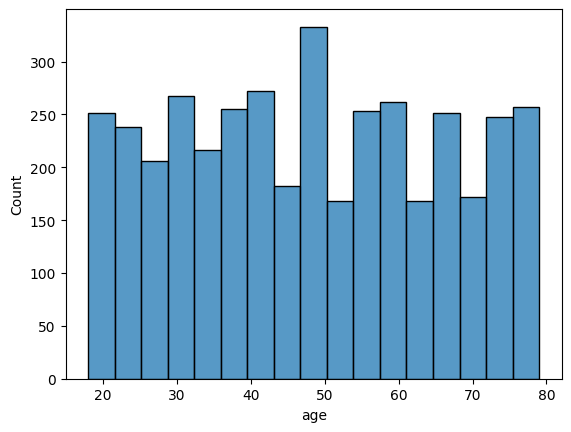

In [45]:

# Histograma para visualizar la edad (age)

sns.histplot(data=user_profile, x='age')
plt.show()



💡Insights: 
- Distribución: La distribución de edades se ve bastante uniforme, con usuarios repartidos de forma pareja entre los 20 y los 80 años, sin un sesgo marcado hacia jóvenes o mayores. Hay un pico notable alrededor de los 45-50 años (cerca de 330 usuarios), pero el resto de las barras están relativamente parejas entre 150 y 270.

Esto es útil porque la base de clientes no está concentrada en un solo grupo etario, sino que es bastante diversa. 

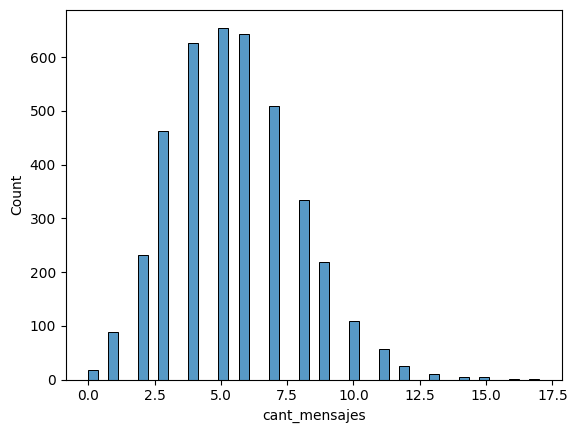

In [46]:
# Histograma para visualizar la cant_mensajes
sns.histplot(data=user_profile, x='cant_mensajes')
plt.show()

💡Insights: 
- Lo que se observa es una distribución asimétrica hacia la derecha (sesgo positivo): la mayoría de los usuarios envían entre 4 y 6 mensajes (donde está el pico más alto, cerca de 650), y a medida que aumenta la cantidad de mensajes, cada vez hay menos usuarios, formando una "cola" larga hacia la derecha hasta los 17-18 mensajes.

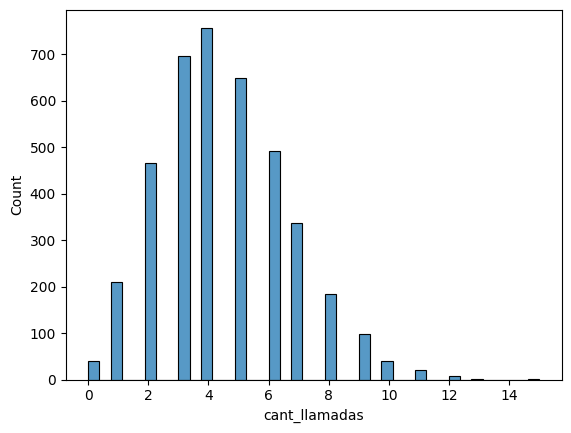

In [47]:
# Histograma para visualizar la cant_llamadas
sns.histplot(data=user_profile, x='cant_llamadas')
plt.show()

💡Insights: 
- una distribución sesgada hacia la derecha, con el pico principal entre 3 y 4 llamadas (cerca de 750 usuarios), y una cola que se extiende hasta 14-15 llamadas con muy pocos usuarios ahí.

Esto confirma el mismo comportamiento: la mayoría de los usuarios tiene un uso moderado, y hay un grupo pequeño de usuarios mucho más activos que estira la distribución hacia la derecha.

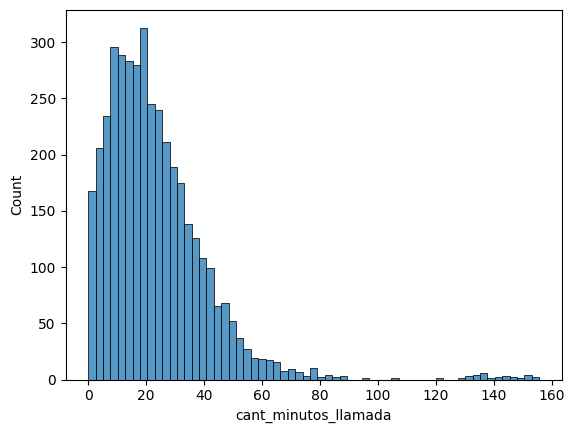

In [48]:
# Histograma para visualizar la cant_minutos_llamada
sns.histplot(data=user_profile, x='cant_minutos_llamada')
plt.show()

💡Insights: 
- muestra un sesgo hacia la derecha: la mayoría de los usuarios acumula entre 10 y 30 minutos totales de llamada, con el pico cerca de 20 minutos, y luego una cola larga que llega hasta 160 minutos con muy pocos usuarios ahí.

Es el mismo patrón que viste en cant_mensajes y cant_llamadas: comportamiento "normal" concentrado en valores bajos, y pocos usuarios muy activos que estiran la distribución.

### 5.2 Identificación de Outliers

🎯 **Objetivo:**  
Detectar valores extremos en las variables clave de **uso** y **clientes** que podrían afectar el análisis, y decidir si requieren limpieza o revisión adicional.

**Instrucciones:**  
- Usa **boxplots** para identificar visualmente outliers en las siguientes columnas:  
  - `age` 
  - `cant_mensajes`
  - `cant_llamadas`
  - `total_minutos_llamada`  
- Crea un **for** para generar los 4 boxplots automáticamente.
<br>

- D
espués de crear los gráfico, responde si **existen o no outliers** en las variables.  
- Si hay outliers, crea otro bucle para calcular los límites de esas columnas usando el **método IQR** y decide qué hacer con ellos.
  - Si solamente hay outliers de un solo lado, no es necesario calcular ambos límites.

**Hint:**
- Dentro del bucle, usa `plt.title(f'Boxplot: {col}')` para que el título cambie acorde a la columna.


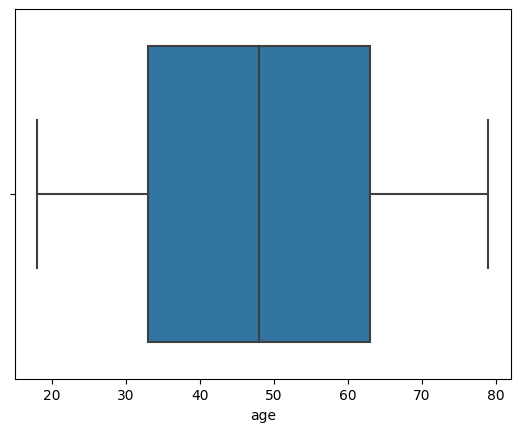

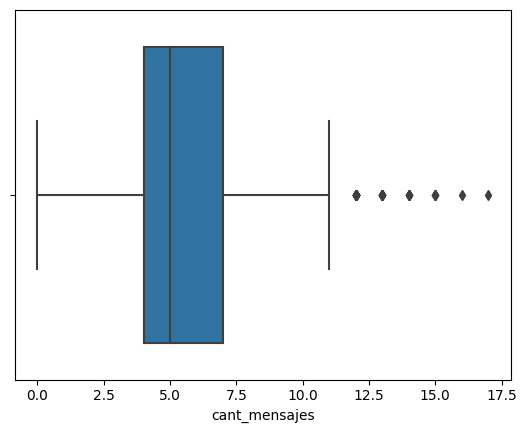

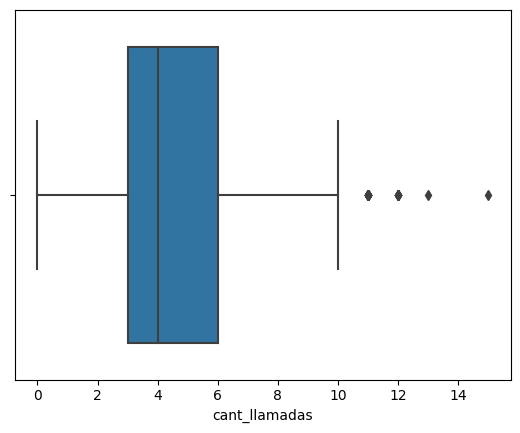

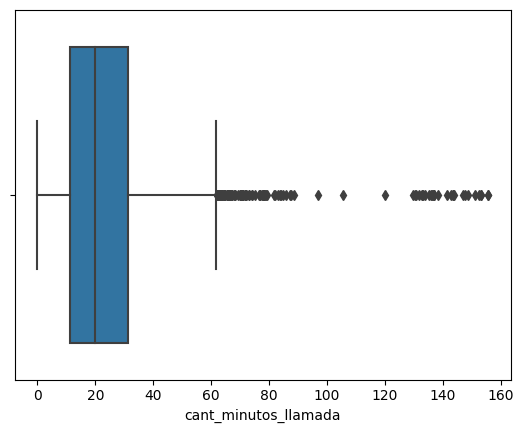

In [49]:

# Visualizando usando BoxPlot 
columnas_numericas = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']


for col in columnas_numericas:
    sns.boxplot(data=user_profile, x=col)
    plt.show()

💡Insights: 
- Age: la caja va desde aproximadamente 33 hasta 63 (donde está el 50% central de los datos), la línea del medio (~48) es la mediana, y los "bigotes" se extienden hasta los valores mínimo y máximo sin que aparezcan puntos sueltos más allá de ellos (sin outliers)
- cant_mensajes: sí hay outliers, esos rombos sueltos a la derecha (entre 12 y 17 mensajes aproximadamente) están fuera del bigote superior (que llega hasta 11), así que son usuarios que envían muchos más mensajes que la mayoría.
Esto coincide con lo que habías visto en el histograma de esta variable, donde notamos ese sesgo positivo con una cola de usuarios muy activos.
- cant_llamadas: El bigote superior llega hasta 10, y esos rombos entre 11 y 15 son outliers, usuarios que hacen bastantes más llamadas que el resto, siendo estos los outliers
- cant_minutos_llamada: el bigote superior llega hasta unos 60 minutos, pero hay muchísimos puntos fuera de ese límite, llegando incluso hasta 150-160 minutos. Es la variable con más outliers de las cuatro, lo cual tiene sentido porque en su histograma vimos el sesgo positivo más pronunciado.

In [50]:

# Calcular límites con el método IQR
columnas_outliers = ['cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']
columnas_limites=[]
for coli in columnas_outliers:
    Q1 = user_profile [coli].quantile(0.25)
    Q3 = user_profile [coli].quantile(0.75)
    IQR = Q3- Q1
    
# calcular límite inferior y superior
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    columnas_limites.append((coli, lower, upper))
print(columnas_limites)



[('cant_mensajes', -0.5, 11.5), ('cant_llamadas', -1.5, 10.5), ('cant_minutos_llamada', -19.322500000000005, 61.8575)]


In [51]:

# Revisa los limites superiores y el max, para tomar la decisión de mantener los outliers o no
user_profile[columnas_outliers].describe()


,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,3999.000000,3999.000000,3999.000000
mean,5.524381,4.478120,23.317054
std,2.358416,2.144238,18.168095
min,0.000000,0.000000,0.000000
25%,4.000000,3.000000,11.120000
50%,5.000000,4.000000,19.780000
75%,7.000000,6.000000,31.415000
max,17.000000,15.000000,155.690000


💡Insights: 
- cant_mensajes: mantener o no outliers, porqué? El valor max es de 17 y comparado con el upper de 11.5 los cuales no coinciden 
- cant_llamadas: mantener o no outliers, porqué? El valor max es de 15 y comparado con el upper de 10.5 los cuales no coinciden
- cant_minutos_llamada: mantener o no outliers, porqué? El valor max es de 155.69 y comparado con el upper de 61.86 los cuales no coinciden
En las tres columnas (cant_mensajes, cant_llamadas, cant_minutos_llamada) la decisión razonable es mantener los outliers, porque:

Representan comportamiento real de usuarios (algunos mensajean, llaman o hablan más que el promedio), no errores de datos.
No hay valores imposibles (como negativos o absurdamente altos para el contexto).
Eliminarlos haría perder información valiosa sobre los usuarios con mayor consumo, que puede ser justamente relevante para el análisis de la empresa (por ejemplo, para ver qué plan usan los que más consumen).

---

## 🧩Paso 6: Segmentación de Clientes

### 6.1 Segmentación de Clientes Por Uso

🎯 **Objetivo:** Clasificar a cada usuario en un grupo de uso (Bajo uso, Uso medio, Alto uso) basándose en la cantidad de llamadas y mensajes registrados.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_uso` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones de llamadas y mensajes y asigna:
  - `'Bajo uso'` cuando llamadas < 5 y mensajes < 5
  - `'Uso medio'` cuando llamadas < 10 y mensajes < 10
  - `'Alto uso'` para el resto de casos

In [52]:
# Crear columna grupo_uso

def clasificar_uso(uso):
    if uso['cant_llamadas'] < 5 and uso['cant_mensajes'] < 5:
        return 'Bajo uso'
    elif uso['cant_llamadas'] < 10 and uso['cant_mensajes'] < 10:
        return 'Uso medio'
    else:
        return 'Alto uso'

user_profile['grupo_uso'] = user_profile.apply(clasificar_uso, axis=1)



In [53]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7,3,23.70,Uso medio
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5,10,33.18,Alto uso
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5,2,10.74,Uso medio
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11,3,8.99,Alto uso
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4,3,8.01,Bajo uso


### 6.2 Segmentación de Clientes Por Edad

🎯 **Objetivo:**: Clasificar a cada usuario en un grupo por **edad**.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_edad` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones y asigna:
  - `'Joven'` cuando age < 30
  - `'Adulto'` cuando age < 60
  - `'Adulto Mayor'` para el resto de casos

In [54]:

# Crear columna grupo_edad
def clasificar_edad(edad):
    if edad['age'] < 30:
        return 'Joven'
    elif edad['age'] < 60:
        return 'Adulto'
    else:
        return 'Adulto mayor'

user_profile['grupo_edad'] = user_profile.apply(clasificar_edad, axis=1)


In [55]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso,grupo_edad
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7,3,23.70,Uso medio,Adulto
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5,10,33.18,Alto uso,Adulto
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5,2,10.74,Uso medio,Adulto
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11,3,8.99,Alto uso,Adulto mayor
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4,3,8.01,Bajo uso,Adulto mayor


### 6.3 Visualización de la Segmentación de Clientes

🎯 **Objetivo:** Visualizar la distribución de los usuarios según los grupos creados: **grupo_uso** y **grupo_edad**.

**Instrucciones:**  
- Crea dos gráficos para las variables categóricas `grupo_uso` y `grupo_edad`.
- Agrega título y etiquetas a los ejes en cada gráfico.

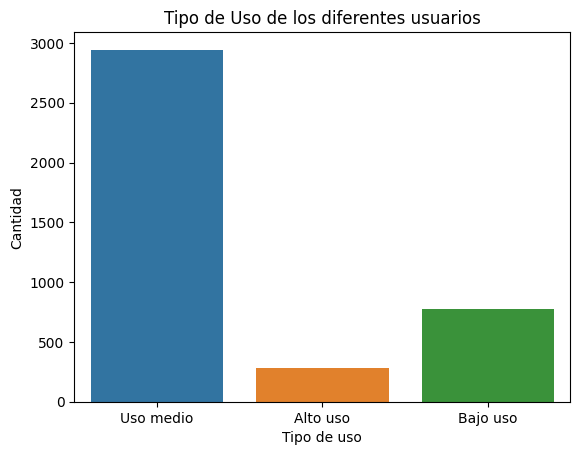

In [56]:
# Visualización de los segmentos por uso

sns.countplot(x='grupo_uso', data=user_profile)
plt.title('Tipo de Uso de los diferentes usuarios')
plt.xlabel('Tipo de uso') 
plt.ylabel('Cantidad')
plt.show()


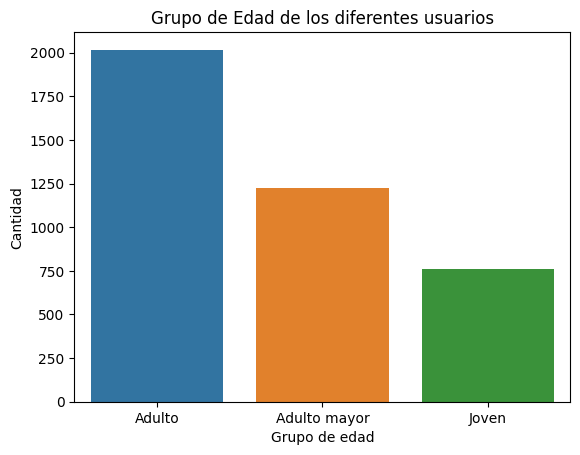

In [57]:
# Visualización de los segmentos por edad
sns.countplot(x='grupo_edad', data=user_profile)
plt.title('Grupo de Edad de los diferentes usuarios')
plt.xlabel('Grupo de edad') 
plt.ylabel('Cantidad')
plt.show()


In [58]:
# Visualización de datos cruzados
pd.crosstab(user_profile['grupo_edad'], user_profile['grupo_uso'], normalize='index')


grupo_uso,Alto uso,Bajo uso,Uso medio
grupo_edad,,,
Adulto,0.075855,0.180466,0.743679
Adulto mayor,0.060556,0.210311,0.729133
Joven,0.067105,0.206579,0.726316



---
## 🧩Paso 7: Insight Ejecutivo para Stakeholders

🎯 **Objetivo:** Traducir los hallazgos del análisis en conclusiones accionables para el negocio, enfocadas en segmentación, patrones de uso y oportunidades comerciales.

**Preguntas a responder:** 
- ¿Qué problemas tenían originalmemte los datos?¿Qué porcentaje, o cantidad de filas, de esa columna representaban?
Habían datos en age el cual era

age: La columna age tenía 55 filas (1.375% del total) con el valor centinela -999, que representaba un dato faltante disfrazado de número válido. Para solucionarlo, reemplacé ese valor por la mediana de la columna.

city: La columna city tenía problemas en 565 filas (14.125% del total): 96 filas (2.4%) usaban el símbolo "?" como marcador de dato faltante, y 469 filas (11.725%) ya venían como nulos (NaN). Convertí los "?" en valores nulos (pd.NA) para unificar el tratamiento de ambos casos.

reg_date: 40 filas (1.0%) tenían fechas de registro en el año 2026, una fecha futura imposible dado que el dataset no puede contener registros aún no ocurridos. Se marcaron esas fechas como nulas. Para reg_date se filtraron esos registros, conservando únicamente las fechas válidas hasta 2024.


- ¿Qué segmentos de clientes identificaste y cómo se comportan según su edad y nivel de uso?
Hay 3 segmentos de grupo, el adulto, adulto mayor y el joven, de acuerdo al nivel de uso para uso medio, los tres grupos están muy cerca entre sí (74.4%, 72.9%, 72.6%). Lo mismo pasa en "Alto uso" (7.6%, 6.1%, 6.7%) y en "Bajo uso" (18%, 21%, 20.6%).
el segmento más numeroso es el de adultos, y el nivel de uso predominante en general es el "uso medio" — pero al cruzar ambas variables con el crosstab normalizado, descubri que la edad no determina el nivel de uso, porque las proporciones son casi idénticas en los tres grupos de edad.

  
- ¿Qué segmentos parecen más valiosos para ConnectaTel y por qué?
los de alto uso son los mas importantes ya que generan mas ganancias, de manera general todas las edad estan cercanas en % de alto uso, el % es bajo por lo que la cantidad de personas que hacen "alto uso" son bajas.


  - ¿Qué patrones de uso extremo (outliers) encontraste y qué implican para el negocio?

cant_mensajes: 17 vs 11.5 → el máximo es poco más de 1.5 veces el límite.
cant_llamadas: 15 vs 10.5 → similar, poco más de 1.4 veces el límite.
cant_minutos_llamada: 155.69 vs 61.86 → aquí el máximo es casi 2.5 veces el límite, mucho más extremo que las otras dos.
Con esto ya puedes distinguir: hay outliers "moderados" (mensajes, llamadas) y outliers "muy marcados" (minutos de llamada).
Los clientes de uso extremo podrían ser candidatos a un plan especial de alto consumo (por ejemplo, con más minutos/mensajes incluidos a un precio ajustado), en lugar de pagar recargos o generar fricción con su plan actual.


- ¿Qué recomendaciones harías para mejorar la oferta actual de planes o crear nuevos planes basados en los segmentos y patrones detectados?

la edad no determina el nivel de uso, no tiene sentido crear planes diferenciados por edad. En cambio, la segmentación debería basarse en el comportamiento real de consumo (bajo, medio, alto), no en características demográficas como la edad.Para los de uso bajo, un plan más básico y económico es conveniente. Y para los de uso medio, ofrecer la opción de migrar a un plan de mayor consumo si lo necesitan también es una recomendación válida, orientada a que no paguen de más ni se queden cortos y asi no pagan un extra.


✍️ **Escribe aquí tu análisis ejecutivo:**

### Análisis ejecutivo

⚠️ **Problemas detectados en los datos**
- age: 55 filas (1.375%) con -999 (dato faltante), imputadas con la mediana.
- city: 565 filas (14.125%) afectadas: 96 con "?" y 469 nulas (NaN), unificadas a pd.NA.
- reg_date: 40 filas (1.0%) con fecha futura (2026), filtradas para conservar solo registros hasta 2024. 


🔍 **Segmentos por Edad**
-Distribución: El grupo de adultos es el más numeroso.  
-Comportamiento: La edad no influye en el consumo; la distribución (Uso Medio ~73%, Bajo ~20%, Alto ~6.5%) es casi idéntica en los tres grupos.


📊 **Segmentos por Nivel de Uso**
-Predominio y valor: Predomina el uso medio (~73%), pero el segmento de alto uso es el más rentable para ConnectaTel.  
-Outliers: Desviaciones moderadas en mensajes y llamadas, y muy marcadas en minutos de llamada (máx. 155.69 vs. límite 61.86).

➡️ Esto sugiere que ...
La segmentación comercial no debe basarse en la edad, sino en el consumo real. Los outliers indican una necesidad no cubierta en clientes de muy alto consumo.

💡 **Recomendaciones**
-Estructura por consumo: Diseñar planes según el nivel de uso (bajo, medio, alto) y no por demografía.  
-Flexibilidad y retención: Crear planes básicos económicos, facilitar la migración desde uso medio y ofrecer un plan especial para usuarios extremos que evite fricciones por recargos. 

---

## 🧩Paso 8 Cargar tu notebook y README a GitHub

🎯 **Objetivo:**  
Entregar tu análisis de forma **profesional**, **documentada** y **versionada**, asegurando que cualquier persona pueda revisar, ejecutar y entender tu trabajo.



### Opción A : Subir archivos desde la interfaz de GitHub (UI)

1. Descarga este notebook (`File → Download .ipynb`).  
2. Entra a tu repositorio en GitHub (por ejemplo `telecom-analysis` o `sprint7-final-project`).  
3. Sube tu notebook **Add file → Upload files**.  

---

### Opción B : Guardar directo desde Google Colab

1. Abre tu notebook en Colab.  
2. Ve a **File → Save a copy in GitHub**.  
3. Selecciona el repositorio y la carpeta correcta (ej: `notebooks/`).  
4. Escribe un mensaje de commit claro, por ejemplo:  
    - `feat: add final ConnectaTel analysis`
    - `agregar version final: Análisis ConnectaTel`
5. Verifica en GitHub que el archivo quedó en el lugar correcto y que el historial de commits se mantenga limpio.

---

Agrega un archivo `README.md` que describa de forma clara:
- el objetivo del proyecto,  
- los datasets utilizados,  
- las etapas del análisis realizadas,  
- cómo ejecutar el notebook (por ejemplo, abrirlo en Google Colab),  
- una breve guía de reproducción.
---

Link a repositorio público del proyecto: `LINK a tu repo aquí`